Heart         mean x=50.00 mean y=50.00  sd x=18.00 sd y=18.00  r=-0.060
Broken heart  mean x=50.00 mean y=50.00  sd x=18.00 sd y=18.00  r=-0.060


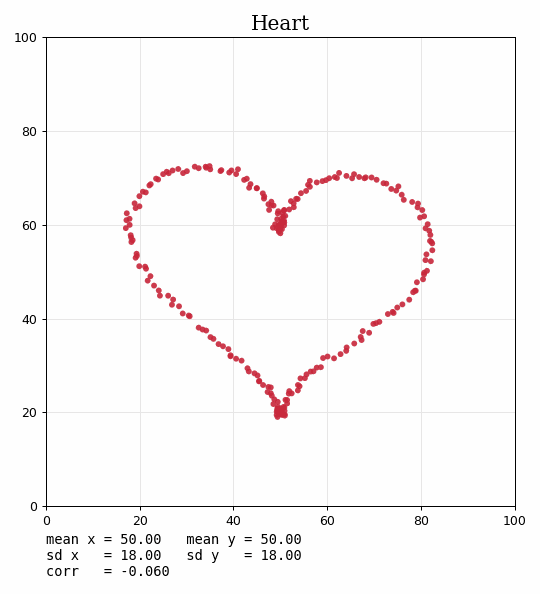

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import numpy as np, io
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from PIL import Image
from scipy.optimize import linear_sum_assignment

rng = np.random.default_rng(7)
N = 240

def heart_xy(t):
    return 16*np.sin(t)**3, 13*np.cos(t)-5*np.cos(2*t)-2*np.cos(3*t)-np.cos(4*t)

# --- Heart
t = np.linspace(0, 2*np.pi, N, endpoint=False) + rng.normal(0, 0.01, N)
H = np.c_[heart_xy(t)] + rng.normal(0, 0.25, (N, 2))

# --- Broken heart (zigzag crack, halves pulled apart)
ys = np.linspace(-16.6, 4.0, 60)
cx = 1.8*(np.abs(((ys+17)/3.1) % 2 - 1)*2 - 1)
nOut = N - 60
t2 = np.linspace(0, 2*np.pi, nOut, endpoint=False) + rng.normal(0, 0.01, nOut)
P = np.c_[heart_xy(t2)] + rng.normal(0, 0.25, (nOut, 2))
left = P[:, 0] < np.interp(P[:, 1], ys, cx)
L, R = P[left], P[~left]
yc = np.linspace(-16.4, 4.0, 30); xc = np.interp(yc, ys, cx)
L = np.vstack([L, np.c_[xc-0.25+rng.normal(0,0.15,30), yc]])
R = np.vstack([R, np.c_[xc+0.25+rng.normal(0,0.15,30), yc]])
def rot(A, deg, c):
    a = np.deg2rad(deg); M = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    return (A-c) @ M.T + c
L = rot(L, 9, np.array([0, -17])) + [-2.6, -1.2]
R = rot(R, -9, np.array([0, -17])) + [2.6, 1.8]
B = np.vstack([L, R])

# --- Force identical mean / SD / correlation (exact, via Cholesky)
def match(D, mx, my, sx, sy, r):
    Z = D - D.mean(0)
    W = Z @ np.linalg.inv(np.linalg.cholesky(np.cov(Z.T, ddof=1))).T
    Z2 = W @ np.array([[1, 0], [r, np.sqrt(1-r*r)]]).T
    return Z2*[sx, sy] + [mx, my]
H = match(H, 50, 50, 18, 18, -0.06)
B = match(B, 50, 50, 18, 18, -0.06)

# --- Pair each heart point with a broken-heart point (smooth morph)
_, col = linear_sum_assignment(((H[:, None, :]-B[None, :, :])**2).sum(-1))
B = B[col]

# --- Save the dataset (this is the file to share)
import pandas as pd
out = pd.DataFrame({"x_heart":H[:,0],"y_heart":H[:,1],
                    "x_broken":B[:,0],"y_broken":B[:,1]}).round(4)
out.to_csv("heart_data.csv", index=False)

# --- Check: statistics computed from the saved points
for name,(a,b) in {"Heart":("x_heart","y_heart"),"Broken heart":("x_broken","y_broken")}.items():
    print(f"{name:13s} mean x={out[a].mean():.2f} mean y={out[b].mean():.2f}  "
          f"sd x={out[a].std():.2f} sd y={out[b].std():.2f}  r={out[a].corr(out[b]):.3f}")

# --- Frames
def stats(D): return D[:,0].mean(), D[:,1].mean(), D[:,0].std(ddof=1), D[:,1].std(ddof=1), np.corrcoef(D.T)[0,1]
def frame(D, title, colour):
    mx, my, sx, sy, r = stats(D)
    fig, ax = plt.subplots(figsize=(6, 6.6), dpi=90)
    ax.scatter(D[:,0], D[:,1], s=22, color=colour, alpha=.9, edgecolor="none")
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.set_aspect("equal")
    ax.grid(color="#e6e6e6"); ax.set_axisbelow(True)
    ax.set_title(title, fontsize=16, family="serif")
    ax.set_xlabel(f"mean x = {mx:.2f}   mean y = {my:.2f}\nsd x   = {sx:.2f}   sd y   = {sy:.2f}\ncorr   = {r:.3f}",
                  family="monospace", fontsize=11, loc="left")
    fig.tight_layout()
    buf = io.BytesIO(); fig.savefig(buf, format="png", facecolor="white"); plt.close(fig)
    buf.seek(0); return Image.open(buf).convert("P", palette=Image.ADAPTIVE)

RED, PURPLE, GREY = "#C8283C", "#5A4E7A", "#555555"
frames, durations = [], []
def hold(D, title, colour, n=10):
    f = frame(D, title, colour); frames.extend([f]*n); durations.extend([80]*n)
def morph(A, Bz, steps=16):
    for t in np.linspace(0, 1, steps)[1:-1]:
        w = (1-np.cos(np.pi*t))/2
        frames.append(frame((1-w)*A + w*Bz, "...", GREY)); durations.append(70)

hold(H, "Heart", RED);           morph(H, B)
hold(B, "Broken heart", PURPLE); morph(B, H)
hold(H, "Heart", RED, n=4)

frames[0].save("heart_morph.gif", save_all=True, append_images=frames[1:],
               duration=durations, loop=0, optimize=False)

# --- Show in Colab
from IPython.display import Image as IPImage, display
display(IPImage("heart_morph.gif"))

# --- Download both files to your computer
from google.colab import files
files.download("heart_morph.gif")
files.download("heart_data.csv")

# Same Statistics. Different Stories.

## Aim
To show why summary statistics alone can be misleading, and why **data visualization and multivariate analysis** are essential, using two bivariate datasets shaped like a heart and a broken heart.

## What this notebook does
1. Builds two datasets of n = 240 points each:
   - **Dataset A:** points forming a heart ❤️
   - **Dataset B:** points forming a broken heart 💔 (a zigzag crack with the two halves pulled apart)
2. Rescales both datasets with a linear transformation (Cholesky) so that they share exactly the same:
   - Mean of X and Y = 50
   - SD of X and Y = 18
   - Pearson correlation r = −0.06
3. Recomputes the statistics from the plotted points to confirm they match.
4. Animates a smooth morph between the two datasets, with the statistics recalculated on every frame.

## Key observation
| Statistic | Heart | Broken heart |
|---|---|---|
| Mean of X | 50.00 | 50.00 |
| Mean of Y | 50.00 | 50.00 |
| SD of X | 18.00 | 18.00 |
| SD of Y | 18.00 | 18.00 |
| Correlation (X, Y) | −0.060 | −0.060 |

The numbers are identical, but the scatterplots look completely different.

## Why this matters
- The mean, SD and correlation describe only the **centre, spread and linear association** of the data. They say nothing about its shape or structure.
- A correlation near zero does not mean "no relationship". Here it hides a clear geometric pattern.
- Always **plot the data** before trusting summary statistics.
- Multivariate analysis and visualization reveal structure that single-number summaries miss.

## Related ideas
- Anscombe's quartet (1973)
- The Datasaurus Dozen (Matejka & Fitzmaurice, 2017)

> *Mean, standard deviation and correlation summarise data, but multivariate analysis helps us understand the structure behind it.*